<a href="https://colab.research.google.com/github/drishikaaneja/flyrank-ml-internship-starter/blob/main/work/notebooks/w05_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# W05 · Capstone Modeling Lane (ML-08)

**Lane:** CTR / Engagement Opportunity Scoring (confirmed in Week 4).

**Goal:** predict how many clicks a page *should* get from its searches, so under-capture can be measured against a fairer expectation than position alone, and check honestly whether a model does that better than my **Week-4 baseline** on the **same data, same split and same metrics**.

Sections, in the skeleton's order:
1. Method choice and why
2. Split design
3. Train + compare vs my baseline
4. Errors and interpretation
5. Self-check

**Same data as Week 4:** only the previous-30-day columns of `fact_content_query_90d` (release `v20260703`), same exclusions (zero impressions in that window, average position below 1). Page features come from `dim_content`. No last-30-day columns and no click-derived features are used as inputs.

**How to run:** Colab secret `HF_TOKEN1` with notebook access on, then **Runtime → Run all**. Takes about 8–12 minutes.

In [2]:
!pip install -q duckdb huggingface_hub

import os, json
import numpy as np
import pandas as pd
import duckdb
import matplotlib.pyplot as plt
from google.colab import userdata
from scipy.stats import spearmanr
from sklearn.model_selection import GroupKFold
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance

HF_TOKEN = userdata.get("HF_TOKEN1")          # Colab secret, never printed
BASE = "hf://datasets/FlyRank/internship-warehouse"
Q = f"{BASE}/fact_content_query_90d.parquet"
C = f"{BASE}/dim_content.parquet"

os.makedirs("work/outputs", exist_ok=True)
os.makedirs("work/figures", exist_ok=True)

con = duckdb.connect()
con.execute(f"CREATE SECRET hf (TYPE huggingface, TOKEN '{HF_TOKEN}')")

EXPECTED_ROWS = 1_995_557          # Week-4 input-window row count; the join must not change it
MIN_PAGE_IMPRESSIONS_30D = 200     # same page threshold as the Week-4 rule
RANDOM_STATE = 42
print("Setup done")

Setup done


## 1 · Method choice and why

**What is predicted:** the click-through rate of each query–page row (clicks ÷ impressions), trained with impressions as sample weights. Multiplying by impressions gives **expected clicks**; summing over a page's queries gives the page's expected clicks. This is exactly the quantity the Week-4 rule estimated, so model and baseline are directly comparable.

**Candidates (from the session menu), simplest first:**

| Method | Why it is here |
|---|---|
| **Week-4 baseline**: pooled CTR by position band | The rule to beat. Uses position only. |
| **Decision tree** (depth 4) | A simple, readable model. Shows whether a few extra splits help at all. |
| **Gradient boosting** (`HistGradientBoostingRegressor`) | Handles non-linear effects and missing values; "where safe" because every input is known in the same window and nothing is derived from clicks. |

Logistic regression and clustering are not used: the target is a rate weighted by impressions (a regression problem), and the lane needs an expected-click estimate, not groups. Random forest would add cost without a clear reason over boosting at this data size.

**Features (8, all known in the input window):** average position, query length in words, query length in characters, page word count, content type, main search intent, keyword competition, keyword search volume.

**Rule for picking a winner:** the model must beat the baseline on the **same split** consistently, not just on average, and extra complexity must earn its place (if the tree matches boosting, the tree wins).

In [3]:
rows = con.sql(f"""
    SELECT q.client_hash_id, q.content_hash_id, q.query_hash_id,
           q.impressions_prev30  AS imp,
           q.clicks_prev30       AS clicks,
           q.avg_position_prev30 AS position,
           q.query_token_count, q.query_char_count,
           c.word_count, c.content_type, c.main_intent, c.competition, c.search_volume
    FROM '{Q}' q
    LEFT JOIN '{C}' c USING (client_hash_id, content_hash_id)
    WHERE q.impressions_prev30 > 0 AND q.avg_position_prev30 >= 1
""").df()

print("Rows:", len(rows), "| expected (Week 4):", EXPECTED_ROWS, "| match:", len(rows) == EXPECTED_ROWS)
print("Pages:", rows.content_hash_id.nunique(), "| Clients:", rows.client_hash_id.nunique())

POS_BINS = [1, 2, 3, 4, 6, 11, 21, np.inf]
POS_LABELS = ["1", "2", "3", "4-5", "6-10", "11-20", "21+"]
rows["pos_band"] = pd.cut(rows["position"].round(), bins=POS_BINS, labels=POS_LABELS, right=False)
rows["ctr"] = rows["clicks"] / rows["imp"]

FEATURES = ["position", "query_token_count", "query_char_count", "word_count",
            "content_type", "main_intent", "competition", "search_volume"]
CAT_COLS = ["content_type", "main_intent"]

X_hgb = rows[FEATURES].copy()
for col in CAT_COLS:
    X_hgb[col] = X_hgb[col].astype("category")

# Numeric copy for the decision tree: category codes, missing values as -1
X_tree = X_hgb.copy()
for col in CAT_COLS:
    X_tree[col] = X_tree[col].cat.codes
X_tree = X_tree.astype(float).fillna(-1)

y = rows["ctr"].values
w = rows["imp"].values
print("Features:", FEATURES)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Rows: 1995557 | expected (Week 4): 1995557 | match: True
Pages: 119131 | Clients: 52
Features: ['position', 'query_token_count', 'query_char_count', 'word_count', 'content_type', 'main_intent', 'competition', 'search_volume']


## 2 · Split design

**5-fold `GroupKFold` grouped by client.** Every row from a client lands in the same fold, so each model is always tested on clients it never saw during training. A random row split would leak: the same pages and the same clients would sit on both sides, flattering any model that memorises them.

**The same five folds are used for all three methods**, and the baseline's position-band CTRs are also learned from the training clients only.

**Evaluation is at page level**, the level the action queue uses: predicted clicks are summed per page and compared with actual clicks for pages with at least 200 impressions (the Week-4 threshold). Metrics:
- **Spearman rank correlation** between predicted and actual page clicks (higher is better). This matters most, because the output is a ranked queue.
- **Mean absolute error** in page clicks (lower is better).
- **Weighted MAE of row CTR** (impression-weighted, lower is better), as a row-level check.

In [4]:
gkf = GroupKFold(n_splits=5)
FOLDS = list(gkf.split(rows, groups=rows["client_hash_id"]))

for i, (tr, te) in enumerate(FOLDS):
    overlap = set(rows["client_hash_id"].iloc[tr]) & set(rows["client_hash_id"].iloc[te])
    print(f"Fold {i+1}: train rows {len(tr):,} | test rows {len(te):,} | "
          f"test clients {rows['client_hash_id'].iloc[te].nunique()} | client overlap: {len(overlap)}")

Fold 1: train rows 1,440,506 | test rows 555,051 | test clients 1 | client overlap: 0
Fold 2: train rows 1,635,420 | test rows 360,137 | test clients 9 | client overlap: 0
Fold 3: train rows 1,635,424 | test rows 360,133 | test clients 12 | client overlap: 0
Fold 4: train rows 1,635,439 | test rows 360,118 | test clients 14 | client overlap: 0
Fold 5: train rows 1,635,439 | test rows 360,118 | test clients 16 | client overlap: 0


## 3 · Train + compare vs my baseline

In [5]:
oof = {name: np.full(len(rows), np.nan) for name in ["baseline", "tree", "boosting"]}
fold_metrics = []
last_model, last_test_idx = None, None

def page_metrics(test_idx, pred_ctr):
    t = rows.iloc[test_idx][["content_hash_id", "imp", "clicks"]].copy()
    t["pred_clicks"] = t["imp"].values * pred_ctr
    pg = t.groupby("content_hash_id")[["imp", "clicks", "pred_clicks"]].sum()
    pg = pg[pg["imp"] >= MIN_PAGE_IMPRESSIONS_30D]
    return {
        "pages": int(len(pg)),
        "page_spearman": float(spearmanr(pg["pred_clicks"], pg["clicks"]).correlation),
        "page_mae": float((pg["pred_clicks"] - pg["clicks"]).abs().mean()),
    }

for i, (tr, te) in enumerate(FOLDS):
    # Baseline: Week-4 rule, position-band CTR learned from training clients only
    tr_rows = rows.iloc[tr]
    band = tr_rows.groupby("pos_band", observed=True)[["clicks", "imp"]].sum()
    band_ctr = (band["clicks"] / band["imp"]).to_dict()
    p_base = rows["pos_band"].iloc[te].map(band_ctr).astype(float).fillna(0).values

    tree = DecisionTreeRegressor(max_depth=4, min_samples_leaf=1000, random_state=RANDOM_STATE)
    tree.fit(X_tree.iloc[tr], y[tr], sample_weight=w[tr])
    p_tree = np.clip(tree.predict(X_tree.iloc[te]), 0, 1)

    hgb = HistGradientBoostingRegressor(categorical_features="from_dtype", max_iter=200, random_state=RANDOM_STATE)
    hgb.fit(X_hgb.iloc[tr], y[tr], sample_weight=w[tr])
    p_hgb = np.clip(hgb.predict(X_hgb.iloc[te]), 0, 1)

    for name, p in [("baseline", p_base), ("tree", p_tree), ("boosting", p_hgb)]:
        oof[name][te] = p
        m = page_metrics(te, p)
        m["row_wmae_ctr"] = float(np.sum(w[te] * np.abs(y[te] - p)) / np.sum(w[te]))
        m.update({"fold": i + 1, "method": name})
        fold_metrics.append(m)

    last_model, last_test_idx = hgb, te
    print(f"Fold {i+1} done")

fm = pd.DataFrame(fold_metrics)
table = fm.pivot(index="fold", columns="method", values="page_spearman")[["baseline", "tree", "boosting"]]
print("\nPage-level Spearman by fold (higher is better):")
print(table.round(3))

Fold 1 done
Fold 2 done
Fold 3 done
Fold 4 done
Fold 5 done

Page-level Spearman by fold (higher is better):
method  baseline   tree  boosting
fold                             
1          0.738  0.745     0.755
2          0.546  0.537     0.525
3          0.632  0.643     0.640
4          0.604  0.616     0.628
5          0.699  0.707     0.713


MODEL vs BASELINE (mean of 5 client-grouped folds, same split, same pages)
          page_spearman  page_mae  row_wmae_ctr  spearman_wins_vs_baseline  mae_wins_vs_baseline
method                                                                                          
baseline         0.6437    3.4384        0.0030                        NaN                   NaN
tree             0.6497    3.5364        0.0031                        4.0                   3.0
boosting         0.6521    3.5482        0.0031                        4.0                   3.0

Chosen method: tree  (Spearman gain over baseline: +0.006)


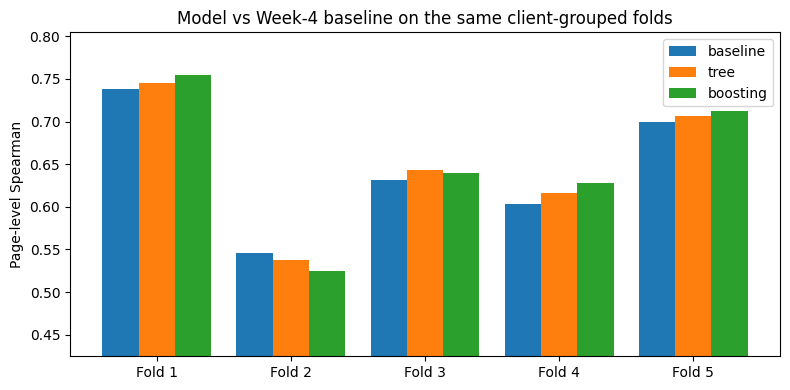

In [6]:
summary = fm.groupby("method")[["page_spearman", "page_mae", "row_wmae_ctr"]].mean().loc[["baseline", "tree", "boosting"]]

def wins(metric, method, higher_is_better):
    a = fm[fm.method == method].set_index("fold")[metric]
    b = fm[fm.method == "baseline"].set_index("fold")[metric]
    return int((a > b).sum() if higher_is_better else (a < b).sum())

summary["spearman_wins_vs_baseline"] = [None, wins("page_spearman", "tree", True), wins("page_spearman", "boosting", True)]
summary["mae_wins_vs_baseline"] = [None, wins("page_mae", "tree", False), wins("page_mae", "boosting", False)]

print("MODEL vs BASELINE (mean of 5 client-grouped folds, same split, same pages)")
print(summary.round(4).to_string())

# Pick the winner honestly: must beat baseline on Spearman in at least 4 of 5 folds;
# prefer the simpler model unless boosting is clearly better.
cand = []
for m in ["tree", "boosting"]:
    if summary.loc[m, "spearman_wins_vs_baseline"] >= 4:
        cand.append(m)
if not cand:
    WINNER = "baseline"
elif cand == ["tree", "boosting"] and summary.loc["boosting", "page_spearman"] - summary.loc["tree", "page_spearman"] < 0.005:
    WINNER = "tree"
else:
    WINNER = max(cand, key=lambda m: summary.loc[m, "page_spearman"])

gain = summary.loc[WINNER, "page_spearman"] - summary.loc["baseline", "page_spearman"] if WINNER != "baseline" else 0.0
print(f"\nChosen method: {WINNER}  (Spearman gain over baseline: {gain:+.3f})")

fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(5)
for k, (name, off) in enumerate([("baseline", -0.27), ("tree", 0.0), ("boosting", 0.27)]):
    ax.bar(x + off, table[name].values, 0.27, label=name)
ax.set_xticks(x); ax.set_xticklabels([f"Fold {i}" for i in range(1, 6)])
ax.set_ylim(max(0, table.values.min() - 0.1), min(1, table.values.max() + 0.05))
ax.set_ylabel("Page-level Spearman")
ax.set_title("Model vs Week-4 baseline on the same client-grouped folds")
ax.legend()
plt.tight_layout()
plt.savefig("work/figures/w05_model_vs_baseline.png", dpi=150)
plt.show()

## 4 · Errors and interpretation

**4a · What drives the boosting model (permutation importance).** Each feature is shuffled on held-out rows from the last fold (a 200,000-row sample, 3 repeats), and the increase in impression-weighted error is measured. A bigger increase means the model relies on that feature more. This describes the model, not cause and effect.

          feature  importance      std
query_token_count    0.000111 0.000097
         position    0.000099 0.000009
    search_volume    0.000020 0.000011
      main_intent    0.000011 0.000002
      competition    0.000006 0.000004
     content_type    0.000000 0.000000
       word_count   -0.000032 0.000009
 query_char_count   -0.000032 0.000042

Most important feature: query_token_count (45% of total positive importance)


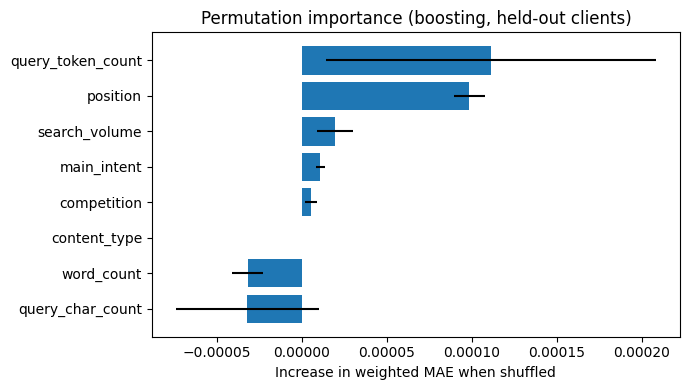

In [7]:
rng = np.random.default_rng(RANDOM_STATE)
sample_idx = rng.choice(last_test_idx, size=min(200_000, len(last_test_idx)), replace=False)

pi = permutation_importance(
    last_model, X_hgb.iloc[sample_idx], y[sample_idx], sample_weight=w[sample_idx],
    scoring="neg_mean_absolute_error", n_repeats=3, random_state=RANDOM_STATE,
)
imp_df = pd.DataFrame({"feature": FEATURES, "importance": pi.importances_mean, "std": pi.importances_std})
imp_df = imp_df.sort_values("importance", ascending=False).reset_index(drop=True)
print(imp_df.to_string(index=False))

top_feature = imp_df.iloc[0]["feature"]
share_top = imp_df.iloc[0]["importance"] / imp_df["importance"].clip(lower=0).sum() if imp_df["importance"].clip(lower=0).sum() > 0 else float("nan")
print(f"\nMost important feature: {top_feature} ({share_top:.0%} of total positive importance)")

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(imp_df["feature"], imp_df["importance"], xerr=imp_df["std"])
ax.invert_yaxis()
ax.set_xlabel("Increase in weighted MAE when shuffled")
ax.set_title("Permutation importance (boosting, held-out clients)")
plt.tight_layout()
plt.savefig("work/figures/w05_permutation_importance.png", dpi=150)
plt.show()

**4b · What the errors look like.** Using out-of-fold predictions from the boosting model, errors are summarised at page level (residual = actual clicks − predicted clicks; negative means the page got fewer clicks than predicted, i.e. it would be flagged as under-capturing):
- by page position band,
- by content type,
- and whether the largest errors are concentrated in pages where one query brings most of the impressions (the Week-4 "weak pick" pattern).

In [8]:
r = rows[["content_hash_id", "query_hash_id", "imp", "clicks", "position", "content_type"]].copy()
r["pred_clicks"] = r["imp"].values * oof["boosting"]
r["pos_x_imp"] = r["position"] * r["imp"]

pg = r.groupby("content_hash_id").agg(
    impressions=("imp", "sum"), clicks=("clicks", "sum"), pred_clicks=("pred_clicks", "sum"),
    pos_x_imp=("pos_x_imp", "sum"), top_query_imp=("imp", "max"),
    content_type=("content_type", "first"),
).reset_index()
pg = pg[pg["impressions"] >= MIN_PAGE_IMPRESSIONS_30D].copy()
pg["position"] = pg["pos_x_imp"] / pg["impressions"]
pg["top_query_share"] = pg["top_query_imp"] / pg["impressions"]
pg["residual"] = pg["clicks"] - pg["pred_clicks"]
pg["abs_error"] = pg["residual"].abs()
pg["pos_band"] = pd.cut(pg["position"].round(), bins=POS_BINS, labels=POS_LABELS, right=False)

by_pos = pg.groupby("pos_band", observed=True).agg(
    pages=("content_hash_id", "size"), mean_residual=("residual", "mean"),
    mae=("abs_error", "mean"), share_under=("residual", lambda s: (s < 0).mean()),
)
print("Errors by page position band:")
print(by_pos.round(2).to_string())

by_type = pg.groupby("content_type", dropna=False).agg(
    pages=("content_hash_id", "size"), mean_residual=("residual", "mean"), mae=("abs_error", "mean"),
).sort_values("pages", ascending=False)
print("\nErrors by content type:")
print(by_type.round(2).to_string())

worst = pg.nlargest(max(1, int(len(pg) * 0.10)), "abs_error")
single_all = (pg["top_query_share"] >= 0.5).mean()
single_worst = (worst["top_query_share"] >= 0.5).mean()
print(f"\nPages where one query brings >=50% of impressions: {single_all:.0%} of all pages, "
      f"{single_worst:.0%} of the 10% largest errors")

err_corr = spearmanr(pg["impressions"], pg["abs_error"]).correlation
print(f"Spearman(page impressions, absolute error) = {err_corr:.2f}")

Errors by page position band:
          pages  mean_residual    mae  share_under
pos_band                                          
1            27          -5.82   7.51         0.70
2           287          -8.87  18.73         0.57
3           657          -5.73  17.22         0.56
4-5        2902          -0.51   8.80         0.55
6-10      12820          -0.37   4.23         0.59
11-20      8230           0.09   1.87         0.62
21+        9834          -0.24   1.00         0.80

Errors by content type:
                    pages  mean_residual   mae
content_type                                  
keyword article     34571          -0.41  3.51
feedly article        134          -1.80  3.52
comparison article     52          -1.18  1.24

Pages where one query brings >=50% of impressions: 12% of all pages, 15% of the 10% largest errors
Spearman(page impressions, absolute error) = 0.63


In [9]:
# Plain-language summary generated from the numbers above
worst_band = by_pos["mae"].idxmax()
most_under_band = by_pos["share_under"].idxmax()
lines = [
    f"- Chosen method: {WINNER}. Mean page-level Spearman: baseline {summary.loc['baseline','page_spearman']:.3f}, "
    f"tree {summary.loc['tree','page_spearman']:.3f}, boosting {summary.loc['boosting','page_spearman']:.3f}.",
    f"- Boosting beat the baseline on Spearman in {int(summary.loc['boosting','spearman_wins_vs_baseline'])} of 5 folds "
    f"and on page MAE in {int(summary.loc['boosting','mae_wins_vs_baseline'])} of 5 folds.",
    f"- The model relies most on '{top_feature}'.",
    f"- Absolute errors are largest for pages in position band {worst_band}; "
    f"band {most_under_band} has the highest share of pages below their predicted clicks ({by_pos.loc[most_under_band,'share_under']:.0%}).",
    (f"- Errors grow with page size (Spearman between impressions and absolute error = {err_corr:.2f}), "
     "so big pages dominate the error in absolute clicks." if err_corr >= 0.3 else
     f"- Errors are only weakly related to page size (Spearman between impressions and absolute error = {err_corr:.2f})."),
    f"- Single-query pages make up {single_all:.0%} of pages but {single_worst:.0%} of the largest errors"
    + (" - over-represented, as Week 4's weak picks suggested." if single_worst > single_all else " - not over-represented."),
]
ERROR_SUMMARY = "\n".join(lines)
print(ERROR_SUMMARY)

- Chosen method: tree. Mean page-level Spearman: baseline 0.644, tree 0.650, boosting 0.652.
- Boosting beat the baseline on Spearman in 4 of 5 folds and on page MAE in 3 of 5 folds.
- The model relies most on 'query_token_count'.
- Absolute errors are largest for pages in position band 2; band 21+ has the highest share of pages below their predicted clicks (80%).
- Errors grow with page size (Spearman between impressions and absolute error = 0.63), so big pages dominate the error in absolute clicks.
- Single-query pages make up 12% of pages but 15% of the largest errors - over-represented, as Week 4's weak picks suggested.


## 5 · Self-check

In [10]:
metrics = {
    "assignment": "ML-08 Capstone Modeling Lane",
    "lane": "CTR / Engagement Opportunity Scoring",
    "release": "v20260703",
    "input_window": "previous 30 days of fact_content_query_90d (same as Week 4)",
    "rows": int(len(rows)),
    "clients": int(rows.client_hash_id.nunique()),
    "features": FEATURES,
    "split": "5-fold GroupKFold by client, identical folds for all methods",
    "page_threshold_impressions": MIN_PAGE_IMPRESSIONS_30D,
    "fold_metrics": fm.to_dict(orient="records"),
    "mean_metrics": {m: {k: float(v) for k, v in summary.loc[m, ["page_spearman", "page_mae", "row_wmae_ctr"]].items()}
                     for m in summary.index},
    "wins_vs_baseline": {m: {"spearman": int(summary.loc[m, "spearman_wins_vs_baseline"]),
                             "mae": int(summary.loc[m, "mae_wins_vs_baseline"])} for m in ["tree", "boosting"]},
    "chosen_method": WINNER,
    "permutation_importance": imp_df.to_dict(orient="records"),
    "errors": {
        "by_position_band": {str(k): {kk: float(vv) for kk, vv in v.items()} for k, v in by_pos.to_dict(orient="index").items()},
        "single_query_share_all_pages": float(single_all),
        "single_query_share_worst10pct": float(single_worst),
        "spearman_impressions_vs_abs_error": float(err_corr),
    },
}
with open("work/outputs/w05_model_metrics.json", "w") as f:
    json.dump(metrics, f, indent=2, default=str)

checks = {
    "Row count matches Week 4 (join added no rows)": len(rows) == EXPECTED_ROWS,
    "No client appears in both train and test in any fold": all(
        not (set(rows["client_hash_id"].iloc[tr]) & set(rows["client_hash_id"].iloc[te])) for tr, te in FOLDS),
    "Baseline and both models scored on the same folds": all(np.isfinite(oof[m]).all() for m in oof),
    "No last-30-day or click-derived inputs": not any(("last30" in f) or ("click" in f) or (f == "ctr") for f in FEATURES),
    "Model-vs-baseline table produced": summary.shape[0] == 3,
    "Permutation importance computed": len(imp_df) == len(FEATURES),
    "Error analysis produced": len(by_pos) > 0 and len(ERROR_SUMMARY) > 0,
    "Metrics JSON written": os.path.exists("work/outputs/w05_model_metrics.json"),
    "Figures written": all(os.path.exists(p) for p in ["work/figures/w05_model_vs_baseline.png",
                                                        "work/figures/w05_permutation_importance.png"]),
}
for name, ok in checks.items():
    print("PASS" if ok else "FAIL", "-", name)
print("\nAll checks passed" if all(checks.values()) else "\nSome checks FAILED - look above")

PASS - Row count matches Week 4 (join added no rows)
PASS - No client appears in both train and test in any fold
PASS - Baseline and both models scored on the same folds
PASS - No last-30-day or click-derived inputs
PASS - Model-vs-baseline table produced
PASS - Permutation importance computed
PASS - Error analysis produced
PASS - Metrics JSON written
PASS - Figures written

All checks passed


### Final model-vs-baseline table

In [11]:
final = summary[["page_spearman", "page_mae", "row_wmae_ctr", "spearman_wins_vs_baseline", "mae_wins_vs_baseline"]].copy()
final.columns = ["Page Spearman (higher better)", "Page MAE clicks (lower better)", "Row weighted MAE CTR (lower better)",
                 "Spearman wins vs baseline (of 5)", "MAE wins vs baseline (of 5)"]
print(final.round(4).to_string())
print("\n" + ERROR_SUMMARY)

          Page Spearman (higher better)  Page MAE clicks (lower better)  Row weighted MAE CTR (lower better)  Spearman wins vs baseline (of 5)  MAE wins vs baseline (of 5)
method                                                                                                                                                                     
baseline                         0.6437                          3.4384                               0.0030                               NaN                          NaN
tree                             0.6497                          3.5364                               0.0031                               4.0                          3.0
boosting                         0.6521                          3.5482                               0.0031                               4.0                          3.0

- Chosen method: tree. Mean page-level Spearman: baseline 0.644, tree 0.650, boosting 0.652.
- Boosting beat the baseline on Spearman in 4 

In [12]:
# Download the files to commit
from google.colab import files
for p in ["work/outputs/w05_model_metrics.json",
          "work/figures/w05_model_vs_baseline.png",
          "work/figures/w05_permutation_importance.png"]:
    files.download(p)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>